REFERANS (BASELINE) MODEL SONUÇLARI
--- Linear Regression Başarısı ---
MSE: 0.04773 | MAE: 0.15055 | R2: -0.45064

--- Artificial Neural Network (ANN) Başarısı ---
MSE: 0.03880 | MAE: 0.15215 | R2: -0.17916



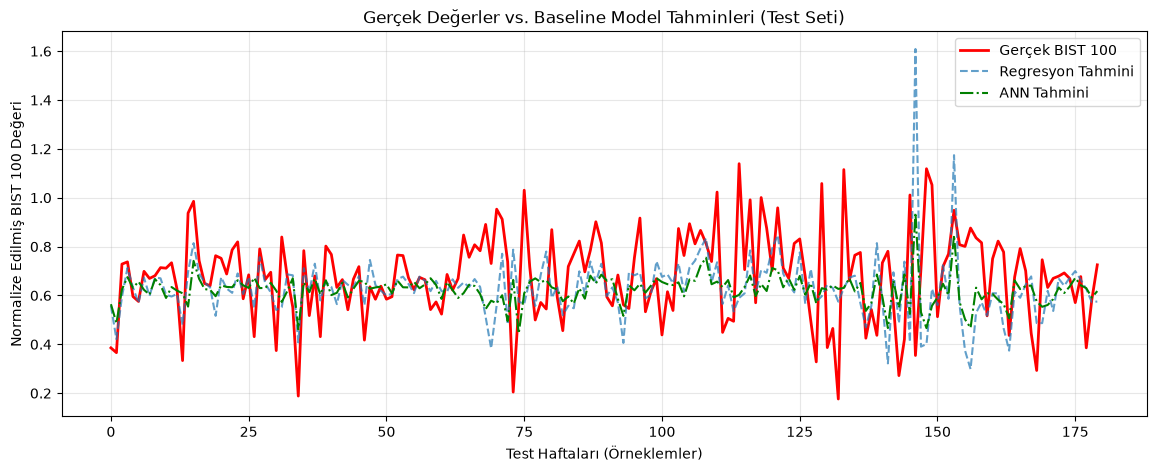

In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import os

data_dir = "../data"

# 1. İşlenmiş Verileri Yükle
train_df = pd.read_csv(os.path.join(data_dir, 'processed_train.csv'), index_col='Date', parse_dates=True)
test_df = pd.read_csv(os.path.join(data_dir, 'processed_test.csv'), index_col='Date', parse_dates=True)

# Girdi (X) ve Çıktı (y) değişkenlerini ayır
X_train = train_df[['GOLD_TL', 'VIX', 'BOND_2Y']]
y_train = train_df['BIST100']
X_test = test_df[['GOLD_TL', 'VIX', 'BOND_2Y']]
y_test = test_df['BIST100']

# 2. ÇOKLU DOĞRUSAL REGRESYON (Makale Bölüm 5.1)
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

# 3. YAPAY SİNİR AĞI (ANN) (Makale Bölüm 4.1)
# Mimari: 1 Gizli Katman, 15 Nöron, Tansig (Tanh) Aktivasyonu
ann_model = MLPRegressor(hidden_layer_sizes=(15,), activation='tanh', solver='adam', 
                         max_iter=2000, random_state=42)
ann_model.fit(X_train, y_train)
ann_preds = ann_model.predict(X_test)

# 4. PERFORMANS DEĞERLENDİRMESİ (Makale Tablo 3)
def evaluate_model(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} Başarısı ---")
    print(f"MSE: {mse:.5f} | MAE: {mae:.5f} | R2: {r2:.5f}\n")
    return mse, mae, r2

print("REFERANS (BASELINE) MODEL SONUÇLARI\n" + "="*35)
evaluate_model(y_test, lr_preds, "Linear Regression")
evaluate_model(y_test, ann_preds, "Artificial Neural Network (ANN)")

# 5. GRAFİKSEL KARŞILAŞTIRMA (Makale Şekil 8 ve 9)
plt.figure(figsize=(14, 5))
plt.plot(y_test.values, label="Gerçek BIST 100", color="red", linewidth=2)
plt.plot(lr_preds, label="Regresyon Tahmini", linestyle="--", alpha=0.7)
plt.plot(ann_preds, label="ANN Tahmini", linestyle="-.", color="green")
plt.title("Gerçek Değerler vs. Baseline Model Tahminleri (Test Seti)")
plt.xlabel("Test Haftaları (Örneklemler)")
plt.ylabel("Normalize Edilmiş BIST 100 Değeri")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('../results/figures/baseline_predictions.png', dpi=300, bbox_inches='tight')
plt.show()